# Lab 18: Fitting the Model

This lab fits the reference Bayesian MMM from Lab 15 and focuses on reading MCMC diagnostics rather than the parameter estimates themselves.
It accompanies Chapter 18 of the book Marketing Mix Modelling.

The reference model is the labs' simplified teaching model: national rather than regional, and with each channel's adstock and saturation fixed at the values the synthetic data were built with, so only the channel scales, the baseline, the promotion and the controls are estimated.
The case-study notebooks for Part IX use `mmm_book.case_model`, which estimates the transforms as well.

In [1]:
import arviz as az
import pymc as pm

from mmm_book import RANDOM_SEED
from mmm_book.plotting import mmm_style
from mmm_book.reference import national_aggregate, reference_model
from mmm_book.sedge import CHANNELS, generate_sedge

mmm_style()

## Building the reference model

This reuses the shared national-aggregate reference model in `mmm_book.reference`: the model Lab 15 builds in stages, with the priors Lab 17 chooses.

In [2]:
df = generate_sedge()
nat = national_aggregate(df)
model = reference_model(nat)
model

         intercept ~ Normal(0.922, 0.175)
             trend ~ Normal(0, 0.175)
          season_a ~ Normal(0, 0.175)
          season_b ~ Normal(0, 0.175)
      omega_launch ~ Normal(0, 0.175)
       delta_promo ~ Normal(0, 0.175)
   gamma_log_price ~ Normal(0, 0.175)
gamma_distribution ~ Normal(0, 0.175)
       gamma_stock ~ Normal(0, 0.175)
 gamma_temperature ~ Normal(0, 0.175)
    gamma_rainfall ~ Normal(0, 0.175)
    gamma_category ~ Normal(0, 0.175)
           beta_tv ~ HalfNormal(0, 0.0922)
       beta_search ~ HalfNormal(0, 0.0922)
         beta_meta ~ HalfNormal(0, 0.0922)
      beta_youtube ~ HalfNormal(0, 0.0922)
          beta_ooh ~ HalfNormal(0, 0.0922)
             sigma ~ HalfNormal(0, 0.175)
                 y ~ Normal(f(beta_ooh, beta_youtube, gamma_category, beta_meta, gamma_rainfall, delta_promo, beta_search, gamma_temperature, omega_launch, season_b, beta_tv, gamma_stock, season_a, intercept, gamma_distribution, trend, gamma_log_price), sigma)

## Sampling

The run uses the settings Chapter 18 asks for: four chains, so that `r_hat` compares several independent runs, 1,000 warm-up steps, 1,000 kept draws per chain, and a target acceptance rate of 0.95.
The higher target makes the sampler take smaller steps.
Two of this model's channel scales (YouTube and OOH) sit close to zero, where the posterior is sharply curved, and the quick run at the end of this lab shows what a less cautious setting produces.

In [3]:
with model:
    idata = pm.sample(
        draws=1000,
        tune=1000,
        chains=4,
        cores=1,
        target_accept=0.95,
        random_seed=RANDOM_SEED,
        progressbar=False,
    )

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [intercept, trend, season_a, season_b, omega_launch, delta_promo, gamma_log_price, gamma_distribution, gamma_stock, gamma_temperature, gamma_rainfall, gamma_category, beta_tv, beta_search, beta_meta, beta_youtube, beta_ooh, sigma]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 25 seconds.


## Step 1 - trace plots

Chapter 18 makes the trace plot the first picture to look at.
It shows each chain's draws in order, next to the marginal density they add up to.
A good one is a fuzzy band that stays level, with the four chains overlapping.
A chain drifting slowly, or chains settled at different levels, means the walker has not yet explored the whole posterior, whatever the summary table says.

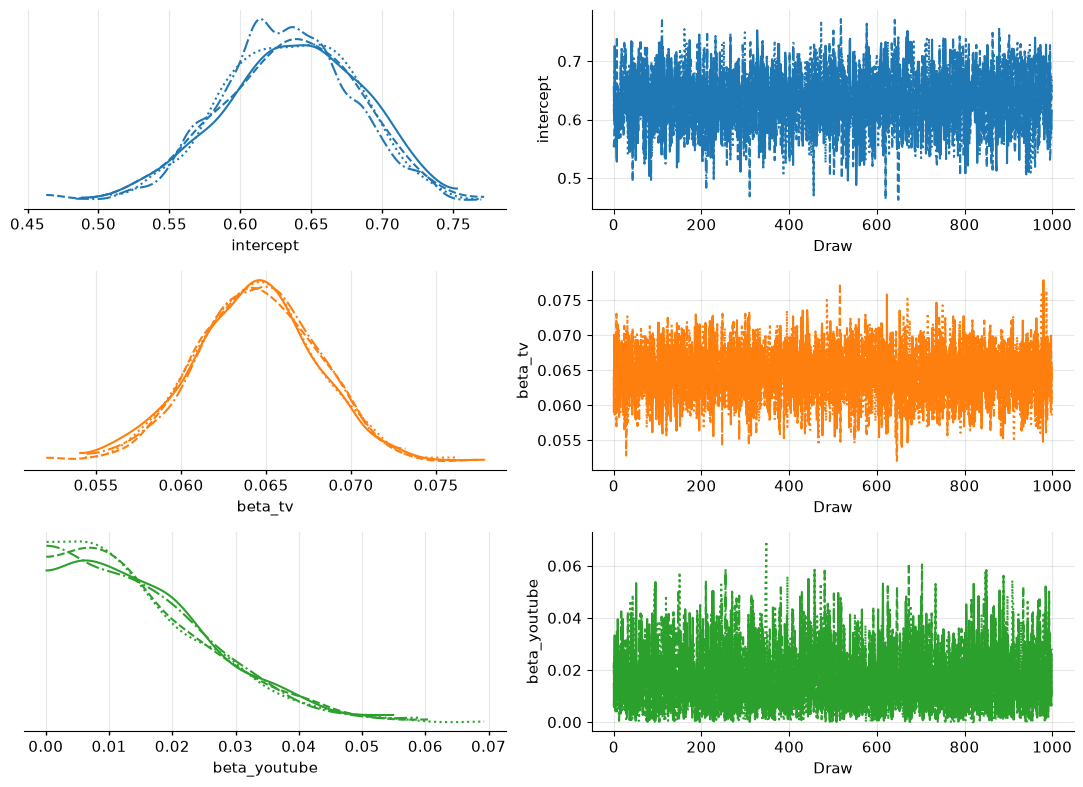

In [4]:
pc = az.plot_trace_dist(
    idata, var_names=["intercept", "beta_tv", "beta_youtube"], figure_kwargs={"figsize": (11, 8)}
)
pc.viz["figure"].item().tight_layout()

## Step 2 - r_hat and effective sample size

`az.summary` reports `r_hat`, which compares between-chain and within-chain variation (values above 1.01 signal chains that have not mixed), and `ess_bulk` / `ess_tail`, the effective number of independent draws behind the bulk and the tails of each posterior.
Chapter 18's guide is at least 100 per chain, so about 400 across four chains, for both.
Low ESS means the ends of the ranges would shift noticeably on a rerun.
The intervals are 90 per cent, as everywhere in the book.

In [5]:
var_names = ["intercept", "trend", "sigma", *[f"beta_{ch}" for ch in CHANNELS]]
summary = az.summary(idata, var_names=var_names, ci_prob=0.9)
print(summary)
full = az.summary(idata, kind="diagnostics")
print(
    f"\nall {len(full)} parameters: largest r_hat {full['r_hat'].max():.3f}, "
    f"smallest bulk ESS {full['ess_bulk'].min():.0f}, "
    f"smallest tail ESS {full['ess_tail'].min():.0f}"
)

                 mean       sd eti90_lb eti90_ub ess_bulk ess_tail r_hat mcse_mean  mcse_sd
intercept       0.635    0.048     0.55     0.71     2146     2108  1.00     0.001  0.00076
trend         0.01421  0.00257     0.01    0.018     3625     3071  1.00   4.3e-05  4.1e-05
sigma         0.02391  0.00143    0.022    0.026     4470     2977  1.00   2.2e-05  2.5e-05
beta_tv        0.0644   0.0035    0.059     0.07     4323     3003  1.00   5.3e-05  5.4e-05
beta_search     0.084    0.039     0.02     0.15     2135     1547  1.00   0.00081  0.00061
beta_meta      0.0887   0.0238    0.046     0.13     3435     2226  1.00   0.00041  0.00037
beta_youtube   0.0157   0.0114   0.0014    0.038     2561     1956  1.00   0.00021  0.00018
beta_ooh        0.026    0.017   0.0025    0.058     2571     1691  1.00   0.00028  0.00023

all 18 parameters: largest r_hat 1.004, smallest bulk ESS 2136, smallest tail ESS 1547


## Step 3 - divergences

Divergences are the sampler flagging regions of the posterior it could not integrate through reliably, a part so steep or narrow that its steps overshoot.
Repeated divergences mean the uncertainty ranges cannot be trusted, and a handful can quietly bias the very estimates a summary table reports.

In [6]:
n_divergent = int(idata.sample_stats["diverging"].sum())
n_draws = idata.posterior.sizes["chain"] * idata.posterior.sizes["draw"]
print(f"Divergent transitions: {n_divergent} out of {n_draws} draws")

Divergent transitions: 0 out of 4000 draws


## Step 4 - the energy plot

The energy plot compares how much the sampler's energy jumps from one draw to the next with how widely it varies across the whole run.
When the two distributions overlap closely, the sampler is exploring the posterior efficiently.
A transition distribution much narrower than the marginal one (a low E-BFMI) means the tails, where downside-risk numbers come from, are explored only slowly.

E-BFMI by chain: [0.95 0.9  0.86 0.96]


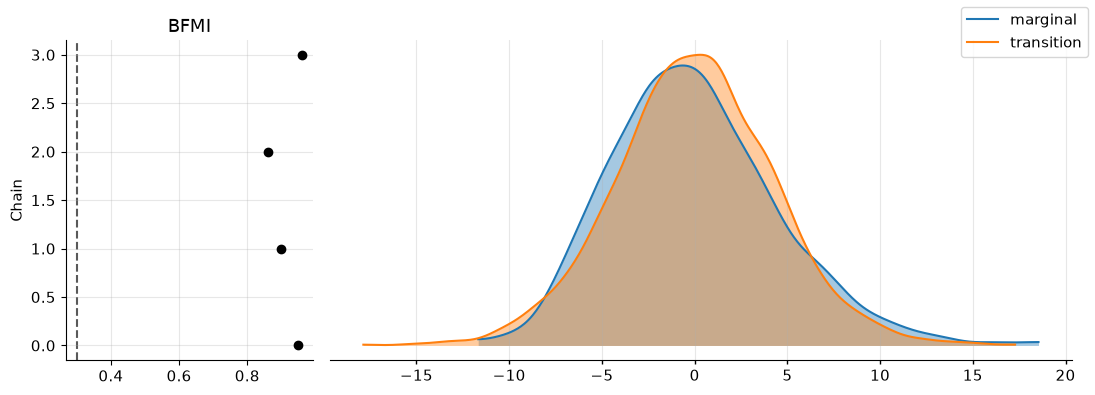

In [7]:
pc = az.plot_energy(idata, figure_kwargs={"figsize": (11, 4)})
pc.viz["figure"].item().tight_layout()
print(f"E-BFMI by chain: {az.bfmi(idata)['energy'].to_numpy().round(2)}")

## What a less careful run looks like

The same model, sampled with two chains of 500 draws, 500 warm-up steps and a target acceptance rate of 0.9, gives a different picture.
This is the kind of quick run that is tempting during development.

In [8]:
with model:
    quick = pm.sample(
        draws=500,
        tune=500,
        chains=2,
        cores=1,
        target_accept=0.9,
        random_seed=RANDOM_SEED,
        progressbar=False,
    )
quick_summary = az.summary(quick, kind="diagnostics")
print(f"divergent transitions: {int(quick.sample_stats['diverging'].sum())}")
print(f"largest r_hat: {quick_summary['r_hat'].max():.3f}")
print(quick_summary.sort_values("r_hat").tail(3)[["ess_bulk", "ess_tail", "r_hat"]])

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (2 chains in 1 job)


NUTS: [intercept, trend, season_a, season_b, omega_launch, delta_promo, gamma_log_price, gamma_distribution, gamma_stock, gamma_temperature, gamma_rainfall, gamma_category, beta_tv, beta_search, beta_meta, beta_youtube, beta_ooh, sigma]


Sampling 2 chains for 500 tune and 500 draw iterations (1_000 + 1_000 draws total) took 6 seconds.


There were 2 divergences after tuning. Increase `target_accept` or reparameterize.


We recommend running at least 4 chains for robust computation of convergence diagnostics


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


divergent transitions: 2
largest r_hat: 1.011
            ess_bulk ess_tail r_hat
intercept        577      599  1.01
delta_promo      472      497  1.01
beta_search      633      516  1.01


The quick run reports divergences and an `r_hat` above 1.01 for some parameters.
Chapter 18 is clear about what that means: the run has failed, and none of its numbers should be used until the warnings are understood and removed.
Working through them in the same order as above:

1. The traces and `r_hat`: with only two short chains, `r_hat` and ESS are themselves noisy, and there are too few chains to see whether separate runs agree, so the first fix is four chains and a longer warm-up.
2. The divergences: there are only a couple, too few to locate (`az.plot_pair(quick, divergences=True)` marks where they fall), so the first remedy is the cautious one, smaller steps through a higher target acceptance rate.
3. Does the fix work? The run at the top of this lab uses both changes and reports no divergences, `r_hat` at or below 1.01 for every parameter and bulk and tail ESS well above 400.

Had the warnings survived those changes, the next step would have been to rewrite the model (Chapter 18's section on when sampling fails), not to sample for longer.

## Takeaway

Look at the trace plots first, then `r_hat` and ESS, then divergences and the energy plot, before reading any estimate off a summary table.
A model can produce numbers even when the sampler failed to explore the posterior properly, and diagnostics are what tell the difference between an estimate and a number.
Warnings are a failed run, to be fixed and rerun; they are never a footnote to an estimate.
Clean diagnostics, as in the main run here, show only that the computation worked: this model fixes the adstock and saturation shapes at their true values, and the diagnostics cannot tell you whether those, or any other modelling choice, are right.